# 실습 6: 정사각형의 시계 방향 60도 회전

필요 패키지: `numpy`, `matplotlib`. 그래프는 실행 결과에 포함됩니다.

회전행렬 A:
[[ 0.5    0.866]
 [-0.866  0.5  ]]

각 꼭짓점의 변환 결과:
P1: (1, 1) → (1.3660, -0.3660)
P2: (1, 2) → (2.2321, 0.1340)
P3: (2, 2) → (2.7321, -0.7321)
P4: (2, 1) → (1.8660, -1.2321)

원점까지의 거리 보존: True


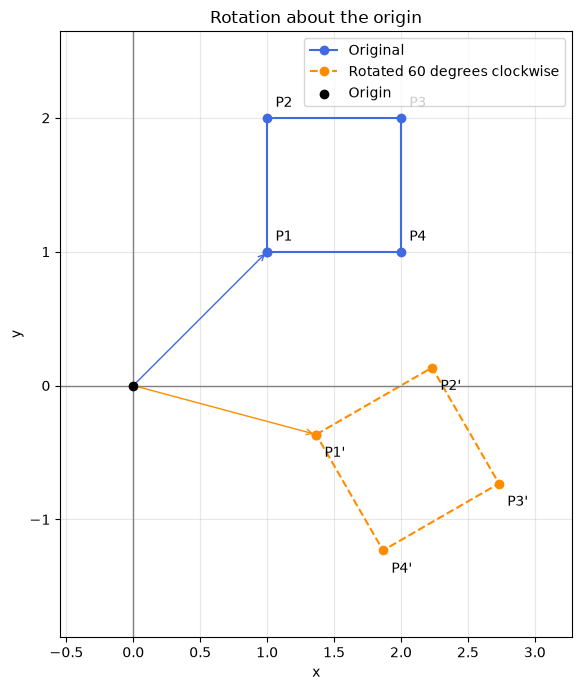

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 회전각: 도(degree)를 라디안으로 변환
theta_deg = 60
theta = np.deg2rad(theta_deg)

# 2. 시계 방향 회전행렬
A = np.array([
    [np.cos(theta), np.sin(theta)],
    [-np.sin(theta), np.cos(theta)],
])

# 3. 각 열이 하나의 꼭짓점인 2×4 행렬
# P1=(1,1), P2=(1,2), P3=(2,2), P4=(2,1)
P = np.array([
    [1, 1, 2, 2],
    [1, 2, 2, 1],
], dtype=float)

# 4. 네 꼭짓점을 한 번에 변환
# (2×2) @ (2×4) = (2×4)
Q = A @ P

np.set_printoptions(precision=4, suppress=True)

print("회전행렬 A:")
print(A)

print("\n각 꼭짓점의 변환 결과:")
for i in range(P.shape[1]):
    print(
        f"P{i + 1}: ({P[0, i]:.0f}, {P[1, i]:.0f})"
        f" → ({Q[0, i]:.4f}, {Q[1, i]:.4f})"
    )

# 5. 원점에서 각 꼭짓점까지의 거리 보존 확인
before = np.linalg.norm(P, axis=0)
after = np.linalg.norm(Q, axis=0)
print("\n원점까지의 거리 보존:", np.allclose(before, after))

# 6. 첫 꼭짓점을 끝에 추가하여 닫힌 정사각형으로 그린다.
P_closed = np.column_stack((P, P[:, 0]))
Q_closed = np.column_stack((Q, Q[:, 0]))
fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    P_closed[0], P_closed[1],
    "o-", color="royalblue", label="Original",
)
ax.plot(
    Q_closed[0], Q_closed[1],
    "o--", color="darkorange",
    label=f"Rotated {theta_deg} degrees clockwise",
)

# 꼭짓점 이름 표시
for i in range(P.shape[1]):
    ax.annotate(
        f"P{i + 1}", P[:, i],
        xytext=(6, 8), textcoords="offset points",
    )
    ax.annotate(
        f"P{i + 1}'", Q[:, i],
        xytext=(6, -16), textcoords="offset points",
    )

# 원점에서 첫 꼭짓점으로 향하는 벡터 표시
for point, color in [(P[:, 0], "royalblue"),
                     (Q[:, 0], "darkorange")]:
    ax.annotate(
        "", xy=point, xytext=(0, 0),
        arrowprops=dict(arrowstyle="->", color=color),
    )

ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)
ax.scatter(0, 0, color="black", zorder=5, label="Origin")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Rotation about the origin")
ax.set_aspect("equal", adjustable="box")  # 가로·세로 눈금 비율 동일
ax.margins(0.2)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()